In [15]:
# Importação de bibliotecas, métricas de avaliação e módulos customizados do projeto

import sys
import os

# Adiciona o diretório pai (raiz do projeto) ao caminho do Python
sys.path.append(os.path.abspath(os.path.join('..')))

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

import numpy as np

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score
)

from src.config import CLASS_NAMES

from pathlib import Path

from src.config import RANDOM_STATE
from src.data.torch_data import create_dataloaders
from src.utils.reproducibility import set_seed
from src.models import MLP
from src.train import train_model

In [2]:
# Carregamento do dataset de tensores de classificação e criação dos DataLoaders

processed_dir = Path("../data/processed")

classification_datasets = torch.load(
    processed_dir / "classification_data.pt",
    weights_only=False
)

classification_loaders = create_dataloaders(
    classification_datasets,
    batch_size=64,
    seed=RANDOM_STATE
)

In [3]:
# Inspeção do primeiro lote de classificação (formatos, tipos de dados e classes presentes)

X_batch, y_batch = next(iter(classification_loaders["train"]))

print("Features:", X_batch.shape)
print("Target:", y_batch.shape)

print("Tipo das features:", X_batch.dtype)
print("Tipo do target:", y_batch.dtype)

print("Classes presentes:", torch.unique(y_batch))

Features: torch.Size([64, 15])
Target: torch.Size([64])
Tipo das features: torch.float32
Tipo do target: torch.int64
Classes presentes: tensor([0, 1, 2])


In [4]:
# Fixação de semente e instanciação da arquitetura MLP baseline para classificação multiclasse (logits)

set_seed(RANDOM_STATE)

model = MLP(
    in_dim=15,
    out_dim=3,
    hidden=(32, 32),
    activation="ReLU",
    dropout=0.0
)

In [5]:
# Definição da função de perda padrão (CrossEntropyLoss) e otimizador Adam (lr=0.001)

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [6]:
# Treinamento do modelo baseline de classificação com monitoramento de validação e early stopping

classification_training_result = train_model(
    model=model,
    train_loader=classification_loaders["train"],
    val_loader=classification_loaders["val"],
    loss_fn=loss_fn,
    optimizer=optimizer,
    epochs=200,
    patience=20
)

Época [1/200] | Train Loss: 0.435738 | Val Loss: 0.342317
Época [2/200] | Train Loss: 0.324032 | Val Loss: 0.320384
Época [3/200] | Train Loss: 0.311465 | Val Loss: 0.316395
Época [4/200] | Train Loss: 0.308555 | Val Loss: 0.321913
Época [5/200] | Train Loss: 0.306496 | Val Loss: 0.317073
Época [6/200] | Train Loss: 0.304836 | Val Loss: 0.310536
Época [7/200] | Train Loss: 0.303614 | Val Loss: 0.310372
Época [8/200] | Train Loss: 0.303050 | Val Loss: 0.309113
Época [9/200] | Train Loss: 0.302184 | Val Loss: 0.310108
Época [10/200] | Train Loss: 0.301042 | Val Loss: 0.308956
Época [11/200] | Train Loss: 0.300883 | Val Loss: 0.308309
Época [12/200] | Train Loss: 0.299731 | Val Loss: 0.307316
Época [13/200] | Train Loss: 0.299748 | Val Loss: 0.314766
Época [14/200] | Train Loss: 0.298508 | Val Loss: 0.307061
Época [15/200] | Train Loss: 0.297829 | Val Loss: 0.307063
Época [16/200] | Train Loss: 0.297123 | Val Loss: 0.307890
Época [17/200] | Train Loss: 0.296881 | Val Loss: 0.305202
Época 

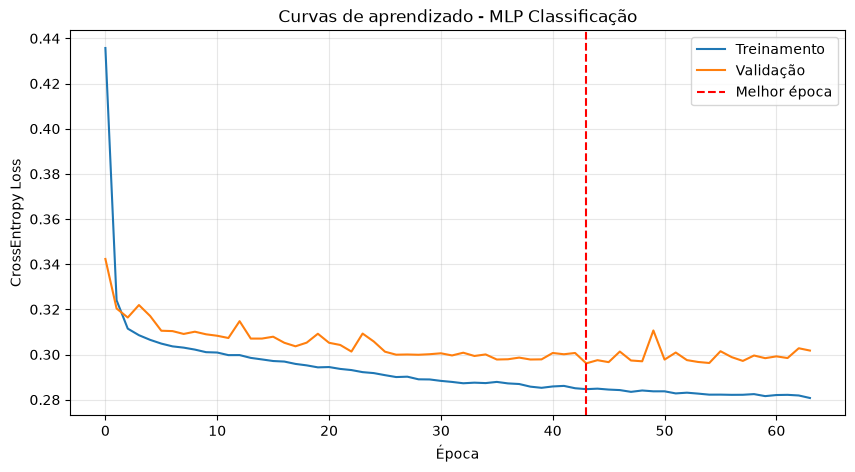

In [7]:
# Visualização gráfica das curvas de aprendizado (treino vs validação) do baseline de classificação

history = classification_training_result["history"]

plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Treinamento")
plt.plot(history["val_loss"], label="Validação")

plt.axvline(
    x=classification_training_result["best_epoch"] - 1,
    color="red",
    linestyle="--",
    label="Melhor época"
)

plt.xlabel("Época")
plt.ylabel("CrossEntropy Loss")
plt.title("Curvas de aprendizado - MLP Classificação")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [8]:
# Cálculo da frequência das classes no treino e determinação de pesos inversos para balanceamento
y_train = classification_datasets["train"].tensors[1]

# Contar a quantidade de registros por classe
class_counts = torch.bincount(y_train)

# Calcular os pesos inversamente proporcionais à frequência
num_classes = len(class_counts)
total_samples = len(y_train)

class_weights = total_samples / (num_classes * class_counts)

print("Quantidade por classe:", class_counts)
print("Pesos por classe:", class_weights)

Quantidade por classe: tensor([  301,  8280, 23419])
Pesos por classe: tensor([35.4374,  1.2882,  0.4555])


In [9]:
# Configuração da função de perda ponderada por classe (CrossEntropyLoss com class weights)

loss_fn_weighted = nn.CrossEntropyLoss(
    weight=class_weights.float()
)

In [10]:
# Instanciação e treinamento do modelo MLP de classificação com a função de perda ponderada

set_seed(RANDOM_STATE)

model_weighted = MLP(
    in_dim=15,
    out_dim=3,
    hidden=(32, 32),
    activation="ReLU",
    dropout=0.0
)

optimizer_weighted = optim.Adam(
    model_weighted.parameters(),
    lr=0.001
)

classification_weighted_result = train_model(
    model=model_weighted,
    train_loader=classification_loaders["train"],
    val_loader=classification_loaders["val"],
    loss_fn=loss_fn_weighted,
    optimizer=optimizer_weighted,
    epochs=200,
    patience=20
)

Época [1/200] | Train Loss: 0.634234 | Val Loss: 0.542877
Época [2/200] | Train Loss: 0.484870 | Val Loss: 0.511411
Época [3/200] | Train Loss: 0.465622 | Val Loss: 0.498978
Época [4/200] | Train Loss: 0.448759 | Val Loss: 0.505462
Época [5/200] | Train Loss: 0.445293 | Val Loss: 0.493500
Época [6/200] | Train Loss: 0.436284 | Val Loss: 0.479939
Época [7/200] | Train Loss: 0.433923 | Val Loss: 0.476104
Época [8/200] | Train Loss: 0.426204 | Val Loss: 0.479112
Época [9/200] | Train Loss: 0.426971 | Val Loss: 0.470275
Época [10/200] | Train Loss: 0.424434 | Val Loss: 0.468239
Época [11/200] | Train Loss: 0.422271 | Val Loss: 0.460174
Época [12/200] | Train Loss: 0.421002 | Val Loss: 0.462299
Época [13/200] | Train Loss: 0.415304 | Val Loss: 0.462975
Época [14/200] | Train Loss: 0.417168 | Val Loss: 0.457098
Época [15/200] | Train Loss: 0.416406 | Val Loss: 0.449564
Época [16/200] | Train Loss: 0.413847 | Val Loss: 0.458388
Época [17/200] | Train Loss: 0.411125 | Val Loss: 0.455063
Época 

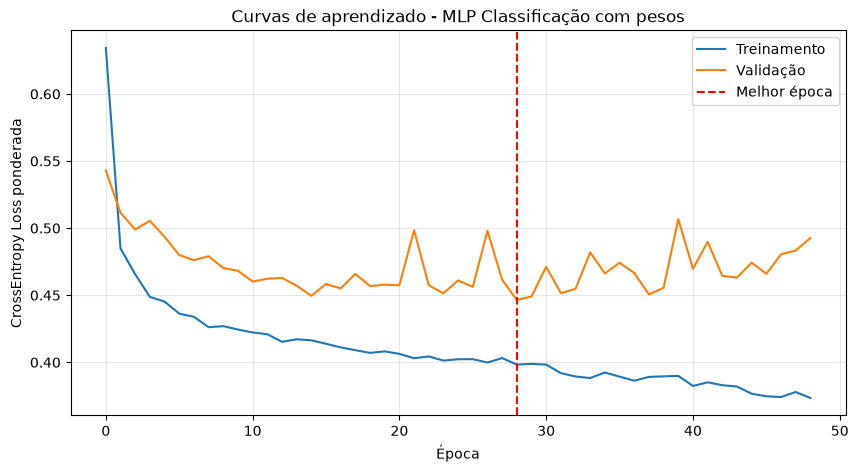

In [11]:
# Visualização gráfica das curvas de aprendizado do modelo de classificação ponderado

history = classification_weighted_result["history"]

plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Treinamento")
plt.plot(history["val_loss"], label="Validação")

plt.axvline(
    x=classification_weighted_result["best_epoch"] - 1,
    color="red",
    linestyle="--",
    label="Melhor época"
)

plt.xlabel("Época")
plt.ylabel("CrossEntropy Loss ponderada")
plt.title("Curvas de aprendizado - MLP Classificação com pesos")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [12]:
# Definição da função auxiliar predict_model para geração de predições e probabilidades

def predict_model(model, data_loader):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            logits = model(X_batch)

            # Converter logits em probabilidades
            probabilities = torch.softmax(logits, dim=1)

            # Selecionar a classe com maior probabilidade
            predictions = torch.argmax(probabilities, dim=1)

            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    return np.array(y_true), np.array(y_pred)

In [13]:
# Geração de predições na validação para o modelo baseline e para o modelo ponderado
y_true, y_pred_baseline = predict_model(
    model,
    classification_loaders["val"]
)

# Modelo com pesos
_, y_pred_weighted = predict_model(
    model_weighted,
    classification_loaders["val"]
)

In [14]:
# Exibição dos relatórios de classificação (Precision, Recall, F1-Score) comparando ambos os modelos

print("=== MODELO BASELINE (SEM PESOS) ===")

print(classification_report(
    y_true,
    y_pred_baseline,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    zero_division=0
))

print("=== MODELO PONDERADO ===")

print(classification_report(
    y_true,
    y_pred_weighted,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    zero_division=0
))

=== MODELO BASELINE (SEM PESOS) ===
              precision    recall  f1-score   support

         Low       0.66      0.36      0.47        75
    Moderate       0.77      0.73      0.75      2070
        High       0.91      0.93      0.92      5855

    accuracy                           0.87      8000
   macro avg       0.78      0.67      0.71      8000
weighted avg       0.87      0.87      0.87      8000

=== MODELO PONDERADO ===
              precision    recall  f1-score   support

         Low       0.20      0.83      0.33        75
    Moderate       0.63      0.75      0.68      2070
        High       0.95      0.85      0.89      5855

    accuracy                           0.82      8000
   macro avg       0.59      0.81      0.63      8000
weighted avg       0.86      0.82      0.83      8000



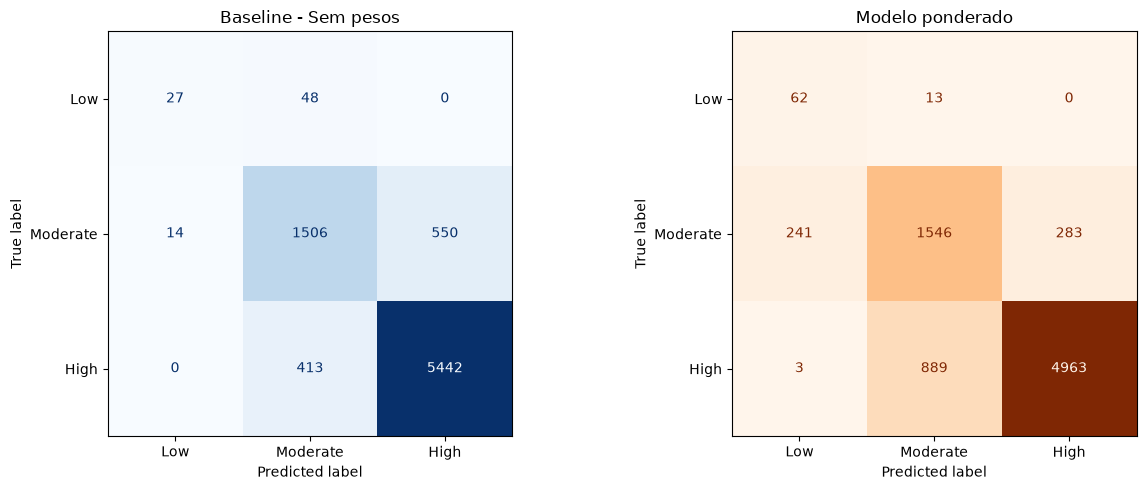

In [16]:
# Plotagem comparativa lado a lado das matrizes de confusão do baseline vs modelo ponderado

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred_baseline,
    labels=[0, 1, 2],
    display_labels=CLASS_NAMES,
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Baseline - Sem pesos")

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred_weighted,
    labels=[0, 1, 2],
    display_labels=CLASS_NAMES,
    cmap="Oranges",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Modelo ponderado")

plt.tight_layout()
plt.show()